# Dissertation Results Tables and Figures
# Fizza Raza - 6509217 - MSC Data Science

## Purpose of this notebook

This notebook contains the final tables and figures used to present the results of the dissertation.

The full data preparation, variable construction, regression modelling, diagnostic checks and sensitivity analyses are documented separately in:

**01_dissertation_analysis_clean_annotated.ipynb**

This notebook is intentionally shorter and focuses only on presenting the final results clearly.

---

## Research question

**Is neighbourhood green-space exposure at age 3 associated with cognitive performance at age 5, after accounting for socioeconomic background and the Home Learning Environment?**

### Exposure

**BGREENSP** — neighbourhood green-space exposure at age 3 (MCS Sweep 2).

An alternative green-space measure, **BGRND**, is used in sensitivity analysis.

### Cognitive outcomes at age 5

1. **Naming Vocabulary** — verbal/language cognition
2. **Pattern Construction** — non-verbal/spatial cognition

### Main covariates

- Child sex
- Household income quintile
- Parental education
- Home Learning Environment (HLE)

### Primary analytical sample

**N = 7,504 children**

The primary BGREENSP analytical sample contains children from the nine English Government Office Regions.

---

## Results outputs

This notebook produces:

1. **Table 1 — Sample selection**
2. **Table 2 — Characteristics of the primary analytical sample**
3. **Table 3 — Hierarchical regression model fit**
4. **Table 4 — Primary green-space regression results**
5. **Table 5 — Robustness and sensitivity analyses**
6. **Figure 1 — BGREENSP coefficients across model specifications**
7. **Figure 2 — Naming Vocabulary across green-space levels**
8. **Figure 3 — Pattern Construction across green-space levels**

The interpretation and discussion of these findings will be written in the dissertation Results and Discussion chapters.

# Table 1 — Sample Selection

## Purpose

This table shows how the analytical sample was obtained from the original age-3 cohort.

The sample became smaller as the analysis required:

1. age-5 cognitive outcome data;
2. Home Learning Environment information;
3. complete background covariates; and
4. availability of the primary BGREENSP green-space measure.

The final primary analytical sample contained **7,504 children**.

In [1]:
# ============================================================
# TABLE 1 — SAMPLE SELECTION
# ============================================================

# ============================================================
# LOAD VERIFIED FINAL PRIMARY ANALYTICAL SAMPLE
# ============================================================

import pandas as pd

primary = pd.read_pickle("primary_final.pkl")

print("Final primary analytical sample loaded.")
print("N =", len(primary))

print(
    "Unique children =",
    primary[["MCSID", "child_num"]]
    .drop_duplicates()
    .shape[0]
)

print(
    "Unique families =",
    primary["MCSID"].nunique()
)
sample_selection = pd.DataFrame({
    "Stage": [
        "Age-3 cohort members",
        "Age-5 cognitive outcomes available",
        "HLE + age-5 outcomes available",
        "Background + HLE + outcomes available",
        "Final sample with BGREENSP available"
    ],
    "N": [
        15770,
        13931,
        13516,
        11767,
        7504
    ],
    "Retained from previous (%)": [
        None,
        88.34,
        97.02,
        87.06,
        63.77
    ],
    "Retained from initial cohort (%)": [
        100.00,
        88.34,
        85.71,
        74.62,
        47.58
    ]
})

sample_selection

Final primary analytical sample loaded.
N = 7504
Unique children = 7504
Unique families = 7410


,Stage,N,Retained from previous (%),Retained from initial cohort (%)
0,Age-3 cohort members,15770,NaN,100.00
1,Age-5 cognitive outcomes available,13931,88.34,88.34
2,HLE + age-5 outcomes available,13516,97.02,85.71
3,Background + HLE + outcomes available,11767,87.06,74.62
4,Final sample with BGREENSP available,7504,63.77,47.58


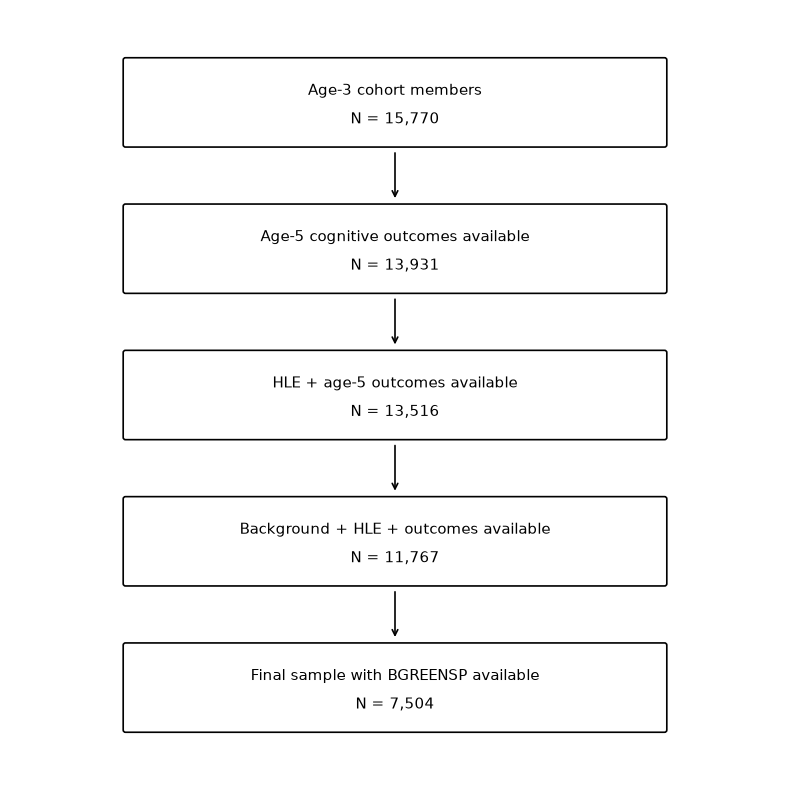

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

stages = [
    ("Age-3 cohort members", "N = 15,770"),
    ("Age-5 cognitive outcomes available", "N = 13,931"),
    ("HLE + age-5 outcomes available", "N = 13,516"),
    ("Background + HLE + outcomes available", "N = 11,767"),
    ("Final sample with BGREENSP available", "N = 7,504"),
]

fig, ax = plt.subplots(figsize=(8, 8))

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

y_positions = [8.8, 6.9, 5.0, 3.1, 1.2]

for i, ((stage, n), y) in enumerate(zip(stages, y_positions)):
    box = FancyBboxPatch(
        (1.5, y - 0.55),
        7,
        1.1,
        boxstyle="round,pad=0.03",
        fill=False,
        linewidth=1.2
    )
    ax.add_patch(box)

    ax.text(
        5, y + 0.15,
        stage,
        ha="center",
        va="center",
        fontsize=11
    )

    ax.text(
        5, y - 0.22,
        n,
        ha="center",
        va="center",
        fontsize=11
    )

    if i < len(y_positions) - 1:
        ax.annotate(
            "",
            xy=(5, y_positions[i + 1] + 0.62),
            xytext=(5, y - 0.62),
            arrowprops=dict(arrowstyle="->", linewidth=1.2)
        )

plt.tight_layout()

plt.savefig(
    "sample_selection_flow.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Table 1 interpretation

The initial age-3 cohort contained **15,770 children**.

After requiring age-5 cognitive outcomes, HLE information and complete background covariates, **11,767 children** remained potentially eligible for the analysis.

Requiring the primary BGREENSP measure reduced the final analytical sample to **7,504 children**.

Therefore:

- **47.6% of the original age-3 cohort** was included in the final primary analysis.
- **63.8% of otherwise eligible children** had BGREENSP information.

The reduction at the final stage was mainly related to the availability of the geographically linked BGREENSP measure.

Later geographical checks confirmed that the final BGREENSP sample contained children from the **nine English Government Office Regions**.

This sample-selection process should be considered when interpreting the generalisability of the findings.

# Table 2 — Characteristics of the Primary Analytical Sample

## Purpose

This table describes the **7,504 children** included in the final primary BGREENSP analysis.

It summarises:

- the two age-5 cognitive outcomes;
- the Home Learning Environment (HLE);
- neighbourhood green-space exposure;
- child sex;
- household income; and
- parental education.

Continuous variables are reported using the **mean and standard deviation (SD)**.

Categorical variables are reported using the **number of children (N) and percentage (%)**.

This table helps describe the analytical sample before presenting the regression results.

In [3]:
# ============================================================
# TABLE 2 — CHARACTERISTICS OF PRIMARY ANALYTICAL SAMPLE
# ============================================================

import pandas as pd

table2 = pd.DataFrame([
    
    # --------------------------------------------------------
    # CONTINUOUS VARIABLES
    # --------------------------------------------------------
    
    {
        "Characteristic": "Naming Vocabulary T-score",
        "N": 7504,
        "Mean (SD) / N (%)": "54.71 (11.29)"
    },
    
    {
        "Characteristic": "Pattern Construction T-score",
        "N": 7504,
        "Mean (SD) / N (%)": "50.67 (10.26)"
    },
    
    {
        "Characteristic": "Home Learning Environment (HLE) score",
        "N": 7504,
        "Mean (SD) / N (%)": "0.03 (0.61)"
    },
    
    {
        "Characteristic": "Neighbourhood green space (BGREENSP)",
        "N": 7504,
        "Mean (SD) / N (%)": "5.31 (2.91)"
    },

    # --------------------------------------------------------
    # CHILD SEX
    # --------------------------------------------------------
    
    {
        "Characteristic": "Child sex — Male",
        "N": 3791,
        "Mean (SD) / N (%)": "3,791 (50.5%)"
    },
    
    {
        "Characteristic": "Child sex — Female",
        "N": 3713,
        "Mean (SD) / N (%)": "3,713 (49.5%)"
    },

    # --------------------------------------------------------
    # HOUSEHOLD INCOME
    # --------------------------------------------------------
    
    {
        "Characteristic": "Income — Lowest quintile",
        "N": 1179,
        "Mean (SD) / N (%)": "1,179 (15.7%)"
    },
    
    {
        "Characteristic": "Income — Second quintile",
        "N": 1468,
        "Mean (SD) / N (%)": "1,468 (19.6%)"
    },
    
    {
        "Characteristic": "Income — Third quintile",
        "N": 1587,
        "Mean (SD) / N (%)": "1,587 (21.1%)"
    },
    
    {
        "Characteristic": "Income — Fourth quintile",
        "N": 1618,
        "Mean (SD) / N (%)": "1,618 (21.6%)"
    },
    
    {
        "Characteristic": "Income — Highest quintile",
        "N": 1652,
        "Mean (SD) / N (%)": "1,652 (22.0%)"
    },

    # --------------------------------------------------------
    # PARENTAL EDUCATION
    # --------------------------------------------------------
    
    {
        "Characteristic": "Parental education — NVQ Level 1",
        "N": 744,
        "Mean (SD) / N (%)": "744 (9.9%)"
    },
    
    {
        "Characteristic": "Parental education — NVQ Level 2",
        "N": 2766,
        "Mean (SD) / N (%)": "2,766 (36.9%)"
    },
    
    {
        "Characteristic": "Parental education — NVQ Level 3",
        "N": 764,
        "Mean (SD) / N (%)": "764 (10.2%)"
    },
    
    {
        "Characteristic": "Parental education — NVQ Level 4",
        "N": 2565,
        "Mean (SD) / N (%)": "2,565 (34.2%)"
    },
    
    {
        "Characteristic": "Parental education — NVQ Level 5",
        "N": 665,
        "Mean (SD) / N (%)": "665 (8.9%)"
    }
])

print("=" * 80)
print("TABLE 2 — CHARACTERISTICS OF THE PRIMARY ANALYTICAL SAMPLE")
print("=" * 80)

display(table2)

TABLE 2 — CHARACTERISTICS OF THE PRIMARY ANALYTICAL SAMPLE


,Characteristic,N,Mean (SD) / N (%)
0,Naming Vocabulary T-score,7504,54.71 (11.29)
1,Pattern Construction T-score,7504,50.67 (10.26)
2,Home Learning Environment (HLE) score,7504,0.03 (0.61)
3,Neighbourhood green space (BGREENSP),7504,5.31 (2.91)
4,Child sex — Male,3791,"3,791 (50.5%)"
5,Child sex — Female,3713,"3,713 (49.5%)"
6,Income — Lowest quintile,1179,"1,179 (15.7%)"
7,Income — Second quintile,1468,"1,468 (19.6%)"
8,Income — Third quintile,1587,"1,587 (21.1%)"
9,Income — Fourth quintile,1618,"1,618 (21.6%)"


### Table 2 interpretation

The final primary analytical sample contained **7,504 children**.

The mean Naming Vocabulary T-score was **54.71 (SD = 11.29)** and the mean Pattern Construction T-score was **50.67 (SD = 10.26)**.

The mean HLE score was **0.03 (SD = 0.61)**, while the mean BGREENSP value was **5.31 (SD = 2.91)**.

The sample was approximately evenly distributed by child sex:

- **50.5% male**
- **49.5% female**

Children were represented across all five household-income quintiles and all five parental-education categories.

There were no missing values for the variables used in the final primary analysis because the primary analytical sample was defined using complete cases.

These descriptive statistics provide the background characteristics of the sample used in the primary regression analyses.

# Table 3 — Hierarchical Regression Model Fit

## Purpose

The primary analysis used hierarchical multiple regression to examine whether neighbourhood green space at age 3 was associated with cognitive outcomes at age 5 after accounting for background socioeconomic factors and the Home Learning Environment (HLE).

The regression models were built in three stages:

### Model 1 — Background characteristics

The first model included:

- child sex;
- household income quintile; and
- parental education.

Household income and parental education were treated as **categorical variables**.

### Model 2 — Add Home Learning Environment

The HLE score was then added to determine whether the home learning environment contributed additional explanatory information beyond the background characteristics.

### Model 3 — Add neighbourhood green space

Finally, BGREENSP was added to determine whether neighbourhood green-space exposure contributed additional explanatory information after accounting for both socioeconomic background and HLE.

Two cognitive outcomes were analysed separately:

1. Naming Vocabulary
2. Pattern Construction

### Understanding the statistics

**R²** represents the proportion of variation in the cognitive outcome accounted for by the variables included in the model.

**Adjusted R²** is a version of R² that also accounts for the number of predictors included in the model.

**ΔR² (change in R²)** shows how much the model R² increased when the next block of variables was added.

The purpose of this table is therefore to show whether adding HLE and then green space improved the explanatory performance of the regression models.

In [4]:
# ============================================================
# TABLE 3 — HIERARCHICAL REGRESSION MODEL FIT
# ============================================================

import pandas as pd

table3 = pd.DataFrame([
    
    # --------------------------------------------------------
    # NAMING VOCABULARY
    # --------------------------------------------------------
    
    {
        "Outcome": "Naming Vocabulary",
        "Model": "Model 1 — Background",
        "R²": 0.1128,
        "Adjusted R²": 0.1117,
        "ΔR²": None
    },
    
    {
        "Outcome": "Naming Vocabulary",
        "Model": "Model 2 — + HLE",
        "R²": 0.1277,
        "Adjusted R²": 0.1265,
        "ΔR²": 0.0149
    },
    
    {
        "Outcome": "Naming Vocabulary",
        "Model": "Model 3 — + Green space",
        "R²": 0.1397,
        "Adjusted R²": 0.1384,
        "ΔR²": 0.0120
    },

    # --------------------------------------------------------
    # PATTERN CONSTRUCTION
    # --------------------------------------------------------
    
    {
        "Outcome": "Pattern Construction",
        "Model": "Model 1 — Background",
        "R²": 0.0536,
        "Adjusted R²": 0.0524,
        "ΔR²": None
    },
    
    {
        "Outcome": "Pattern Construction",
        "Model": "Model 2 — + HLE",
        "R²": 0.0561,
        "Adjusted R²": 0.0549,
        "ΔR²": 0.0025
    },
    
    {
        "Outcome": "Pattern Construction",
        "Model": "Model 3 — + Green space",
        "R²": 0.0566,
        "Adjusted R²": 0.0552,
        "ΔR²": 0.0005
    }
])

print("=" * 85)
print("TABLE 3 — HIERARCHICAL REGRESSION MODEL FIT")
print("=" * 85)

display(table3)

TABLE 3 — HIERARCHICAL REGRESSION MODEL FIT


,Outcome,Model,R²,Adjusted R²,ΔR²
0,Naming Vocabulary,Model 1 — Background,0.1128,0.1117,NaN
1,Naming Vocabulary,Model 2 — + HLE,0.1277,0.1265,0.0149
2,Naming Vocabulary,Model 3 — + Green space,0.1397,0.1384,0.0120
3,Pattern Construction,Model 1 — Background,0.0536,0.0524,NaN
4,Pattern Construction,Model 2 — + HLE,0.0561,0.0549,0.0025
5,Pattern Construction,Model 3 — + Green space,0.0566,0.0552,0.0005


### Table 3 interpretation

The hierarchical regression results show different patterns for the two cognitive outcomes.

## Naming Vocabulary

The background variables in Model 1 accounted for approximately **11.3% of the variation in Naming Vocabulary scores** (R² = 0.1128).

Adding the Home Learning Environment in Model 2 increased R² from:

**0.1128 → 0.1277**

This was an increase of:

**ΔR² = 0.0149**

or approximately **1.5 percentage points**.

Adding neighbourhood green space in Model 3 increased R² further from:

**0.1277 → 0.1397**

This was an additional:

**ΔR² = 0.0120**

or approximately **1.2 percentage points**.

The final model therefore accounted for approximately **14.0% of the variation in Naming Vocabulary scores**.

This suggests that neighbourhood green space contributed additional explanatory information for Vocabulary after the measured background characteristics and HLE had already been included.

However, R² alone does not tell us the direction or statistical uncertainty of the green-space association. The BGREENSP regression coefficient is therefore examined separately in the following results.

---

## Pattern Construction

For Pattern Construction, the background model accounted for approximately **5.4% of the variation in scores** (R² = 0.0536).

Adding HLE increased R² from:

**0.0536 → 0.0561**

giving:

**ΔR² = 0.0025**

or approximately **0.25 percentage points**.

Adding neighbourhood green space produced only a very small further increase:

**0.0561 → 0.0566**

giving:

**ΔR² = 0.0005**

or approximately **0.05 percentage points**.

The final model accounted for approximately **5.7% of the variation in Pattern Construction scores**.

Therefore, adding neighbourhood green space provided very little additional explanatory information for Pattern Construction once background characteristics and HLE had already been included.

---

## What does this tell me in simple terms?

The step-by-step model building suggests a clear difference between the two outcomes.

### 🗣️ Naming Vocabulary

Adding green space made a noticeable, although modest, improvement to the amount of variation accounted for by the model.

### 🧩 Pattern Construction

Adding green space made almost no difference to the amount of variation accounted for by the model.

The next step is to examine the **BGREENSP regression coefficient, confidence interval and p-value** to determine the direction, size and statistical uncertainty of the association.

# Table 4 — Primary Green-Space Regression Results

## Purpose

Table 3 showed how the overall regression model changed when neighbourhood green space was added.

This table now focuses specifically on the **BGREENSP coefficient from the final primary model (Model 3)**.

The coefficient tells me:

- the **direction** of the estimated association;
- the **size** of the estimated association;
- the **uncertainty** around that estimate; and
- whether the data provide statistical evidence that the coefficient differs from zero.

The primary models adjust for:

- child sex;
- household income quintile;
- parental education; and
- Home Learning Environment (HLE).

Household income and parental education are treated as categorical variables.

## Understanding the columns

**B** = the unstandardised regression coefficient.

It represents the estimated difference in the cognitive T-score associated with a one-unit increase in BGREENSP, holding the other variables in the model constant.

**SE** = standard error of the coefficient.

**95% CI** = 95% confidence interval around the estimated coefficient.

**p-value** = statistical evidence against a coefficient of zero.

The coefficient represents an **association**, not a causal effect.

In [5]:
# ============================================================
# TABLE 4 — PRIMARY GREEN-SPACE REGRESSION RESULTS
# ============================================================

import pandas as pd

table4 = pd.DataFrame([
    {
        "Outcome": "Naming Vocabulary",
        "N": 7504,
        "B": 0.4280,
        "SE": 0.0419,
        "95% CI": "[0.346, 0.510]",
        "p": "< .001"
    },
    {
        "Outcome": "Pattern Construction",
        "N": 7504,
        "B": 0.0778,
        "SE": 0.0399,
        "95% CI": "[-0.0004, 0.156]",
        "p": ".051"
    }
])

print("=" * 85)
print("TABLE 4 — PRIMARY GREEN-SPACE REGRESSION RESULTS")
print("=" * 85)

display(table4)

TABLE 4 — PRIMARY GREEN-SPACE REGRESSION RESULTS


,Outcome,N,B,SE,95% CI,p
0,Naming Vocabulary,7504,0.4280,0.0419,"[0.346, 0.510]",< .001
1,Pattern Construction,7504,0.0778,0.0399,"[-0.0004, 0.156]",.051


### Table 4 interpretation

## Naming Vocabulary

In the final primary model, neighbourhood green space was positively associated with Naming Vocabulary:

- **B = 0.428**
- **SE = 0.042**
- **95% CI = [0.346, 0.510]**
- **p < .001**

Holding child sex, household income, parental education and HLE constant, a one-unit higher BGREENSP value was associated with an estimated **0.43-point higher Naming Vocabulary T-score**.

The confidence interval was entirely above zero and the p-value was below .001, providing statistical evidence of a positive association in the primary model.

This result should not be interpreted as evidence that green space caused higher Vocabulary scores.

---

## Pattern Construction

For Pattern Construction, the estimated BGREENSP coefficient was:

- **B = 0.078**
- **SE = 0.040**
- **95% CI = [-0.0004, 0.156]**
- **p = .051**

The estimated association was positive but very small.

The confidence interval included zero by a very small amount and the p-value was just above the conventional .05 threshold.

Therefore, the primary model did **not provide clear statistical evidence** of an independent association between BGREENSP and Pattern Construction.

---

## What does this mean in simple terms?

### 🗣️ Naming Vocabulary

In the main regression model, children with higher neighbourhood green-space exposure tended to have somewhat higher Vocabulary scores, even after the measured socioeconomic factors and HLE were taken into account.

### 🧩 Pattern Construction

The estimated relationship was much smaller and the evidence was uncertain.

Therefore, the primary analysis suggested a clearer green-space association for **Vocabulary** than for **Pattern Construction**.

However, this is not yet the final conclusion.

The next step compares these primary estimates with the robustness and sensitivity analyses to determine how stable they are under different analytical assumptions.

# Table 5 — Robustness and Sensitivity Analyses

## Purpose

The primary regression provides one estimate of the relationship between neighbourhood green space and cognitive outcomes.

However, a result is more convincing if the general conclusion remains similar when reasonable analytical choices are changed.

Therefore, several **robustness and sensitivity checks** were conducted.

In simple terms, these analyses ask:

> **If I analyse the same research question in slightly different reasonable ways, does the result stay similar or does it change substantially?**

The following checks were used:

### HC3 robust standard errors

This changes how the uncertainty around the regression coefficient is estimated and makes inference less dependent on the assumption of equal residual variance.

### Family-cluster robust standard errors

This allows observations from children belonging to the same family to be correlated.

### Alternative green-space measure — BGRND

This examines whether a similar result is obtained using a different measure of neighbourhood green space.

### Region-adjusted model

Government Office Region is added as a categorical covariate to examine whether broader geographical differences account for part of the observed association.

### MCS survey-design sensitivity analysis

This incorporates the MCS survey weight, strata and PSU information to examine how accounting for the complex survey design changes the estimated association.

### Region + survey-design model

Finally, region adjustment and the MCS survey-design information are incorporated together.

This provides a combined sensitivity check incorporating both geographical adjustment and the MCS survey design.

The purpose of these checks is not to search for a statistically significant result.

Instead, they show how dependent the estimated green-space association is on different reasonable modelling assumptions.

In [6]:
# ============================================================
# TABLE 5 — ROBUSTNESS AND SENSITIVITY ANALYSES
# ============================================================

import pandas as pd

table5 = pd.DataFrame([
    
    # --------------------------------------------------------
    # NAMING VOCABULARY
    # --------------------------------------------------------
    
    {
        "Outcome": "Naming Vocabulary",
        "Analysis": "Primary model",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.4280,
        "SE": 0.0419,
        "95% CI": "[0.346, 0.510]",
        "p": "< .001"
    },
    {
        "Outcome": "Naming Vocabulary",
        "Analysis": "HC3 robust SE",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.4280,
        "SE": 0.0420,
        "95% CI": "[0.346, 0.510]",
        "p": "< .001"
    },
    {
        "Outcome": "Naming Vocabulary",
        "Analysis": "Family-cluster robust SE",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.4280,
        "SE": 0.0422,
        "95% CI": "[0.345, 0.511]",
        "p": "< .001"
    },
    {
        "Outcome": "Naming Vocabulary",
        "Analysis": "Alternative green-space measure",
        "Exposure": "BGRND",
        "N": 11766,
        "B": 0.4254,
        "SE": 0.0360,
        "95% CI": "[0.355, 0.496]",
        "p": "< .001"
    },
    {
        "Outcome": "Naming Vocabulary",
        "Analysis": "Region adjusted",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.2795,
        "SE": 0.0452,
        "95% CI": "[0.191, 0.368]",
        "p": "< .001"
    },
    {
        "Outcome": "Naming Vocabulary",
        "Analysis": "MCS survey design",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.1903,
        "SE": 0.0586,
        "95% CI": "[0.076, 0.305]",
        "p": ".001"
    },
    {
        "Outcome": "Naming Vocabulary",
        "Analysis": "Region + survey design",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.1054,
        "SE": 0.0582,
        "95% CI": "[-0.009, 0.220]",
        "p": ".070"
    },

    # --------------------------------------------------------
    # PATTERN CONSTRUCTION
    # --------------------------------------------------------
    
    {
        "Outcome": "Pattern Construction",
        "Analysis": "Primary model",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.0778,
        "SE": 0.0399,
        "95% CI": "[-0.0004, 0.156]",
        "p": ".051"
    },
    {
        "Outcome": "Pattern Construction",
        "Analysis": "HC3 robust SE",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.0778,
        "SE": 0.0391,
        "95% CI": "[0.001, 0.154]",
        "p": ".047"
    },
    {
        "Outcome": "Pattern Construction",
        "Analysis": "Family-cluster robust SE",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.0778,
        "SE": 0.0393,
        "95% CI": "[0.001, 0.155]",
        "p": ".048"
    },
    {
        "Outcome": "Pattern Construction",
        "Analysis": "Alternative green-space measure",
        "Exposure": "BGRND",
        "N": 11766,
        "B": 0.0322,
        "SE": 0.0347,
        "95% CI": "[-0.036, 0.100]",
        "p": ".353"
    },
    {
        "Outcome": "Pattern Construction",
        "Analysis": "Region adjusted",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.0857,
        "SE": 0.0432,
        "95% CI": "[0.001, 0.170]",
        "p": ".047"
    },
    {
        "Outcome": "Pattern Construction",
        "Analysis": "MCS survey design",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": -0.0306,
        "SE": 0.0620,
        "95% CI": "[-0.152, 0.091]",
        "p": ".621"
    },
    {
        "Outcome": "Pattern Construction",
        "Analysis": "Region + survey design",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.0089,
        "SE": 0.0631,
        "95% CI": "[-0.115, 0.133]",
        "p": ".887"
    }
])

print("=" * 105)
print("TABLE 5 — ROBUSTNESS AND SENSITIVITY ANALYSES")
print("=" * 105)

display(table5)

TABLE 5 — ROBUSTNESS AND SENSITIVITY ANALYSES


,Outcome,Analysis,Exposure,N,B,SE,95% CI,p
0,Naming Vocabulary,Primary model,BGREENSP,7504,0.4280,0.0419,"[0.346, 0.510]",< .001
1,Naming Vocabulary,HC3 robust SE,BGREENSP,7504,0.4280,0.0420,"[0.346, 0.510]",< .001
2,Naming Vocabulary,Family-cluster robust SE,BGREENSP,7504,0.4280,0.0422,"[0.345, 0.511]",< .001
3,Naming Vocabulary,Alternative green-space measure,BGRND,11766,0.4254,0.0360,"[0.355, 0.496]",< .001
4,Naming Vocabulary,Region adjusted,BGREENSP,7504,0.2795,0.0452,"[0.191, 0.368]",< .001
5,Naming Vocabulary,MCS survey design,BGREENSP,7504,0.1903,0.0586,"[0.076, 0.305]",.001
6,Naming Vocabulary,Region + survey design,BGREENSP,7504,0.1054,0.0582,"[-0.009, 0.220]",.070
7,Pattern Construction,Primary model,BGREENSP,7504,0.0778,0.0399,"[-0.0004, 0.156]",.051
8,Pattern Construction,HC3 robust SE,BGREENSP,7504,0.0778,0.0391,"[0.001, 0.154]",.047
9,Pattern Construction,Family-cluster robust SE,BGREENSP,7504,0.0778,0.0393,"[0.001, 0.155]",.048


### Table 5 interpretation

The sensitivity analyses show that the findings differ considerably between the two cognitive outcomes.

## Naming Vocabulary

The primary analysis produced a positive association:

**B = 0.428, p < .001**

Changing only the method used to estimate the standard errors had almost no effect.

The HC3 and family-cluster analyses produced essentially the same coefficient and confidence interval as the primary model.

The alternative BGRND measure also produced a similar positive estimate:

**B = 0.425, p < .001**

However, the estimate became smaller when geographical and survey-design factors were considered.

After adjustment for Government Office Region:

**B = 0.280, p < .001**

After incorporating the MCS survey design:

**B = 0.190, p = .001**

When region and survey-design adjustment were incorporated together:

**B = 0.105, p = .070**

The confidence interval in the combined model included zero.

### Interpretation

The positive Vocabulary association seen in the primary analysis is therefore **sensitive to geographical and survey-design adjustment**.

The direction of the coefficient remained positive, but its magnitude progressively decreased:

**0.428 → 0.280 → 0.190 → 0.105**

This suggests that broader geographical and survey-design factors account for part of the association observed in the simpler primary model.

The final evidence should therefore not be described as proving a robust independent green-space effect on Vocabulary.

A more appropriate conclusion is that the primary analysis identified a positive association, but the strength of this association was substantially attenuated under more conservative sensitivity specifications.

---

## Pattern Construction

The primary estimate for Pattern Construction was already very small:

**B = 0.078, p = .051**

HC3, family-cluster and region-adjusted models produced p-values just below .05, but the estimated coefficients remained small.

More importantly, the association was not reproduced when using:

- the alternative BGRND exposure;
- the MCS survey-design analysis; or
- the combined region + survey-design model.

In the combined model:

**B = 0.009, p = .887**

which is very close to zero.

### Interpretation

There is therefore **no consistent evidence of an independent association between neighbourhood green space and Pattern Construction**.

The small changes around the conventional p = .05 threshold should not be treated as evidence of a reliable effect because the estimated association is weak and does not remain consistent across the broader sensitivity analyses.

---

# Overall sensitivity-analysis conclusion

The sensitivity analyses change how the primary results should be interpreted.

### Naming Vocabulary

The primary model identified a positive association, but the estimated coefficient became substantially smaller after geographical and survey-design adjustment.

Therefore, the Vocabulary association appears **sensitive to these adjustments**.

### Pattern Construction

The estimated association was small from the beginning and inconsistent across analyses.

Therefore, there is **no convincing evidence of a stable association with Pattern Construction**.

These analyses strengthen the dissertation because they show that the primary regression result was critically examined rather than accepted without further testing.

# Figure 1 — BGREENSP Coefficients Across Model Specifications

## Purpose

Table 5 presents the numerical results from the robustness and sensitivity analyses.

This figure provides a visual comparison of the estimated BGREENSP coefficients and their 95% confidence intervals across the main model specifications.

The figure focuses on analyses using **BGREENSP**, so that the estimates refer to the same green-space exposure and primary analytical sample.

The alternative BGRND sensitivity analysis remains reported separately in Table 5.

The vertical reference line at **B = 0** represents no estimated association.

If a confidence interval crosses zero, the data are compatible with both a small positive and a small negative association at the 95% confidence level.

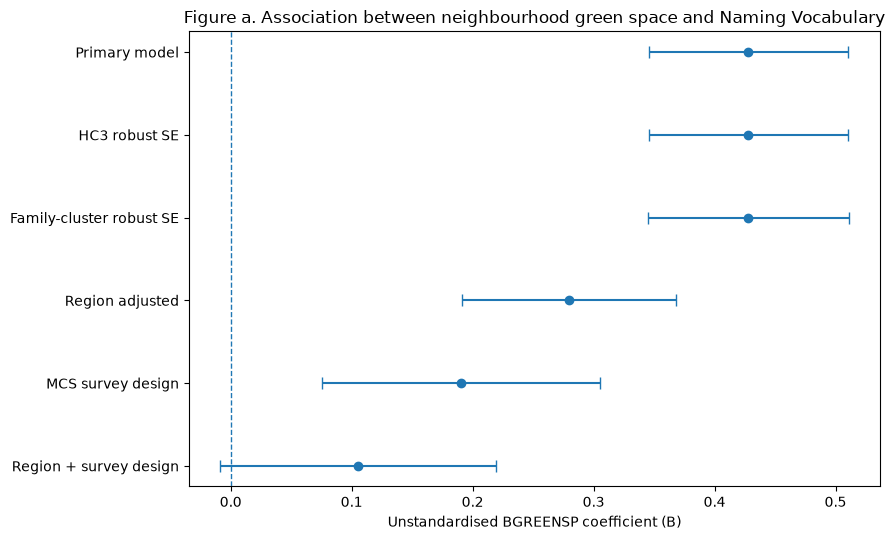

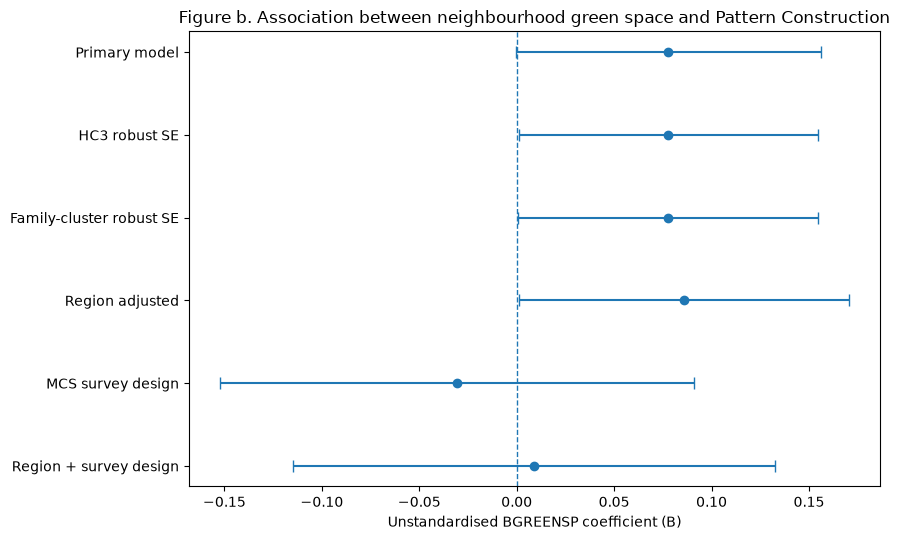

In [7]:
# ============================================================
# FIGURE 1 — BGREENSP COEFFICIENTS ACROSS MODEL SPECIFICATIONS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

figure1 = pd.DataFrame([
    # Vocabulary
    ["Naming Vocabulary", "Primary model", 0.4280, 0.3458, 0.5102],
    ["Naming Vocabulary", "HC3 robust SE", 0.4280, 0.3457, 0.5102],
    ["Naming Vocabulary", "Family-cluster robust SE", 0.4280, 0.3452, 0.5108],
    ["Naming Vocabulary", "Region adjusted", 0.2795, 0.1909, 0.3681],
    ["Naming Vocabulary", "MCS survey design", 0.1903, 0.0755, 0.3052],
    ["Naming Vocabulary", "Region + survey design", 0.1054, -0.0086, 0.2195],

    # Pattern Construction
    ["Pattern Construction", "Primary model", 0.0778, -0.0004, 0.1560],
    ["Pattern Construction", "HC3 robust SE", 0.0778, 0.0011, 0.1544],
    ["Pattern Construction", "Family-cluster robust SE", 0.0778, 0.0007, 0.1548],
    ["Pattern Construction", "Region adjusted", 0.0857, 0.0010, 0.1703],
    ["Pattern Construction", "MCS survey design", -0.0306, -0.1521, 0.0908],
    ["Pattern Construction", "Region + survey design", 0.0089, -0.1148, 0.1327]
], columns=["Outcome", "Analysis", "B", "CI_low", "CI_high"])


for outcome in ["Naming Vocabulary", "Pattern Construction"]:

    plot_data = figure1[
        figure1["Outcome"] == outcome
    ].copy()

    # Reverse order so Primary appears at the top
    plot_data = plot_data.iloc[::-1]

    y = range(len(plot_data))

    lower_error = plot_data["B"] - plot_data["CI_low"]
    upper_error = plot_data["CI_high"] - plot_data["B"]

    plt.figure(figsize=(9, 5.5))

    plt.errorbar(
        plot_data["B"],
        y,
        xerr=[lower_error, upper_error],
        fmt="o",
        capsize=4
    )

    plt.axvline(
        x=0,
        linestyle="--",
        linewidth=1
    )

    plt.yticks(
        y,
        plot_data["Analysis"]
    )

    plt.xlabel("Unstandardised BGREENSP coefficient (B)")
    plt.ylabel("")

    if outcome == "Naming Vocabulary":
      figure_title = ("Figure a. Association between neighbourhood green space and Naming Vocabulary")
       
    else:
     figure_title = (
        "Figure b. Association between neighbourhood green space and Pattern Construction")

    plt.title(figure_title)

    plt.tight_layout()
    plt.show()

**Figure 1. Association between neighbourhood green space and cognitive outcomes across model specifications.**

**Note.** Points represent unstandardised BGREENSP regression coefficients and horizontal lines represent 95% confidence intervals. The dashed vertical line represents the null value (B = 0). All models adjust for child sex, household income, parental education and Home Learning Environment (HLE), with additional adjustments indicated by the model specification. Figure 1a presents Naming Vocabulary and Figure 1b presents Pattern Construction.
### Figure 1 interpretation

The coefficient plots visually demonstrate the different patterns observed for the two cognitive outcomes.

## Naming Vocabulary

The primary, HC3 and family-cluster estimates are almost identical.

However, the estimated BGREENSP coefficient becomes progressively smaller when broader geographical and survey-design factors are incorporated.

The coefficient decreases from approximately:

**0.43 in the primary model**

to:

**0.28 after region adjustment**

**0.19 after survey-design adjustment**

and:

**0.11 in the combined region + survey-design analysis.**

In the combined specification, the 95% confidence interval crosses the zero reference line.

The figure therefore illustrates why the Vocabulary finding should be described as a **positive primary association that is sensitive to geographical and survey-design adjustment**, rather than as a uniformly robust association.

## Pattern Construction

The Pattern Construction coefficients are much closer to zero across the analyses.

The confidence intervals also frequently include or lie very close to zero.

The survey-design and combined region + survey-design estimates are particularly close to zero.

The figure therefore supports the conclusion that there is **no consistent evidence of an independent BGREENSP association with Pattern Construction**.

# Figure 2 — Descriptive Relationship Between Green Space and Naming Vocabulary

## Purpose

The regression analysis estimates the association between neighbourhood green space and cognitive outcomes after accounting for other variables.

Before considering the adjusted regression results, it is also useful to examine what the relationship looks like directly in the observed data.

BGREENSP is measured from **1 to 10**, representing increasing levels of neighbourhood green-space exposure.

This figure shows the **mean Naming Vocabulary T-score at each BGREENSP level**.

The error bars show 95% confidence intervals around each mean.

### Important

This is a **descriptive, unadjusted figure**.

It does not control for child sex, household income, parental education, HLE, region or the MCS survey design.

Therefore, this figure should be used to describe the pattern in the raw analytical sample rather than as evidence of an independent green-space association.

,BGREENSP,count,mean,std,SE,CI_low,CI_high
0,1.0,795,52.95,12.51,0.44,52.08,53.82
1,2.0,970,52.59,11.59,0.37,51.86,53.32
2,3.0,743,53.19,12.47,0.46,52.30,54.09
3,4.0,735,54.56,11.23,0.41,53.75,55.38
4,5.0,698,54.34,10.93,0.41,53.53,55.15
5,6.0,769,54.49,10.66,0.38,53.73,55.24
6,7.0,629,55.37,10.48,0.42,54.55,56.19
7,8.0,818,55.76,10.38,0.36,55.05,56.47
8,9.0,598,56.82,10.58,0.43,55.97,57.67
9,10.0,749,58.19,10.21,0.37,57.46,58.93


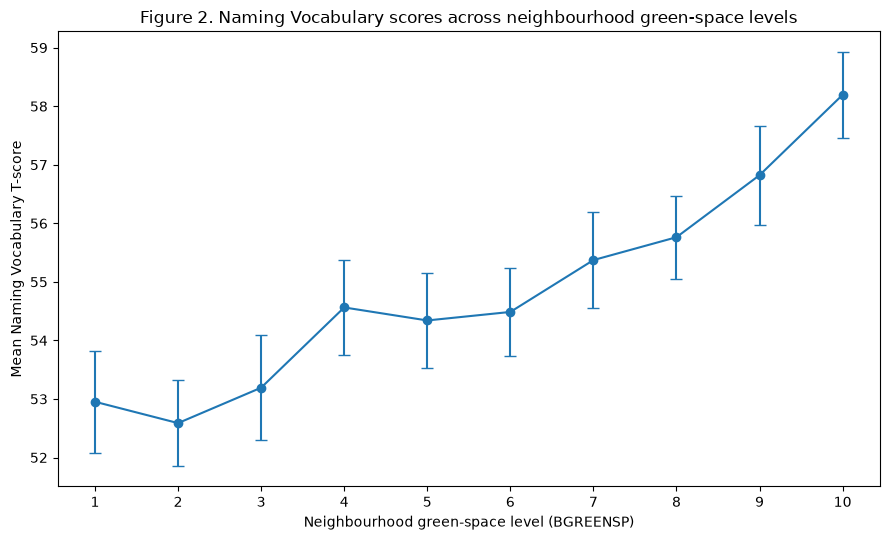

In [8]:
# ============================================================
# FIGURE 2 — GREEN SPACE AND NAMING VOCABULARY
# Descriptive / unadjusted relationship
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# CALCULATE MEAN VOCABULARY SCORE AT EACH BGREENSP LEVEL
# ------------------------------------------------------------

fig2_data = (
    primary
    .groupby("BGREENSP")["vocabulary_tscore"]
    .agg(["count", "mean", "std"])
    .reset_index()
)

# Standard error of the mean
fig2_data["SE"] = (
    fig2_data["std"] / np.sqrt(fig2_data["count"])
)

# Approximate 95% confidence interval
fig2_data["CI_low"] = (
    fig2_data["mean"] - 1.96 * fig2_data["SE"]
)

fig2_data["CI_high"] = (
    fig2_data["mean"] + 1.96 * fig2_data["SE"]
)

display(fig2_data.round(2))


# ------------------------------------------------------------
# CREATE FIGURE
# ------------------------------------------------------------

plt.figure(figsize=(9, 5.5))

plt.errorbar(
    fig2_data["BGREENSP"],
    fig2_data["mean"],
    yerr=[
        fig2_data["mean"] - fig2_data["CI_low"],
        fig2_data["CI_high"] - fig2_data["mean"]
    ],
    fmt="o-",
    capsize=4
)

plt.xlabel("Neighbourhood green-space level (BGREENSP)")
plt.ylabel("Mean Naming Vocabulary T-score")

plt.title(
    "Figure 2. Naming Vocabulary scores across "
    "neighbourhood green-space levels"
)

plt.xticks(range(1, 11))

plt.tight_layout()
plt.show()

# Figure 3 — Descriptive Relationship Between Green Space and Pattern Construction

## Purpose

This figure examines the descriptive relationship between neighbourhood green-space exposure and Pattern Construction scores.

As in Figure 2, children are grouped according to their BGREENSP level from 1 to 10.

The figure shows the **mean Pattern Construction T-score at each BGREENSP level**, together with 95% confidence intervals.

This allows the raw pattern in the analytical sample to be visually compared with the corresponding Naming Vocabulary pattern.

### Important

This figure is **descriptive and unadjusted**.

It does not account for socioeconomic characteristics, HLE, geographical region or the MCS survey design.

The adjusted regression and sensitivity analyses remain the main evidence used to answer the research question.

,BGREENSP,count,mean,std,SE,CI_low,CI_high
0,1.0,795,50.52,10.08,0.36,49.82,51.22
1,2.0,970,50.22,9.78,0.31,49.60,50.83
2,3.0,743,49.73,11.20,0.41,48.92,50.54
3,4.0,735,50.65,10.64,0.39,49.88,51.42
4,5.0,698,50.41,10.65,0.40,49.62,51.20
5,6.0,769,50.73,10.24,0.37,50.00,51.45
6,7.0,629,50.62,9.58,0.38,49.87,51.37
7,8.0,818,51.22,10.22,0.36,50.52,51.92
8,9.0,598,51.25,10.81,0.44,50.38,52.11
9,10.0,749,51.56,9.35,0.34,50.89,52.23


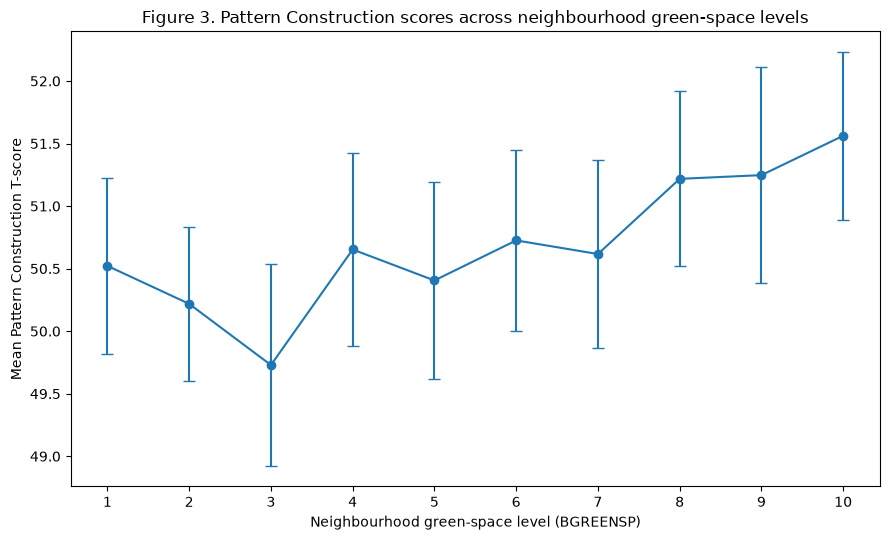

In [9]:
# ============================================================
# FIGURE 3 — GREEN SPACE AND PATTERN CONSTRUCTION
# Descriptive / unadjusted relationship
# ============================================================

# ------------------------------------------------------------
# CALCULATE MEAN PATTERN CONSTRUCTION SCORE
# AT EACH BGREENSP LEVEL
# ------------------------------------------------------------

fig3_data = (
    primary
    .groupby("BGREENSP")["pattern_tscore"]
    .agg(["count", "mean", "std"])
    .reset_index()
)

# Standard error
fig3_data["SE"] = (
    fig3_data["std"] / np.sqrt(fig3_data["count"])
)

# Approximate 95% confidence interval
fig3_data["CI_low"] = (
    fig3_data["mean"] - 1.96 * fig3_data["SE"]
)

fig3_data["CI_high"] = (
    fig3_data["mean"] + 1.96 * fig3_data["SE"]
)

display(fig3_data.round(2))


# ------------------------------------------------------------
# CREATE FIGURE
# ------------------------------------------------------------

plt.figure(figsize=(9, 5.5))

plt.errorbar(
    fig3_data["BGREENSP"],
    fig3_data["mean"],
    yerr=[
        fig3_data["mean"] - fig3_data["CI_low"],
        fig3_data["CI_high"] - fig3_data["mean"]
    ],
    fmt="o-",
    capsize=4
)

plt.xlabel("Neighbourhood green-space level (BGREENSP)")
plt.ylabel("Mean Pattern Construction T-score")

plt.title(
    "Figure 3. Pattern Construction scores across "
    "neighbourhood green-space levels"
)

plt.xticks(range(1, 11))

plt.tight_layout()
plt.show()

## Interpretation of Figures 2 and 3

### Figure 2 — Naming Vocabulary

Figure 2 shows the **raw, unadjusted relationship** between neighbourhood green-space level and Naming Vocabulary scores.

There is a fairly clear overall upward pattern.

Children at the lowest green-space levels had mean Vocabulary scores of approximately:

- BGREENSP 1: **52.95**
- BGREENSP 2: **52.59**
- BGREENSP 3: **53.19**

At the highest green-space levels, the mean scores were higher:

- BGREENSP 8: **55.76**
- BGREENSP 9: **56.82**
- BGREENSP 10: **58.19**

For example, the mean Vocabulary score was approximately **5.24 points higher** at BGREENSP level 10 than at level 1.

The relationship is not perfectly increasing at every single level. For example, there are small decreases between levels 1–2 and 4–5. However, the overall descriptive pattern is clearly upward.

### What does this mean?

Before controlling for any other characteristics, children living in areas with higher BGREENSP levels tended to have higher Naming Vocabulary scores.

However, this graph alone cannot tell us that green space is responsible for the difference.

Children living in greener areas may also differ in other ways, such as:

- household income
- parental education
- Home Learning Environment
- geographical region

This is why the regression models were needed.

The adjusted primary regression showed that the positive association became smaller after accounting for measured background characteristics, and the later region and survey-design sensitivity analyses reduced it further.

Therefore, Figure 2 is useful for showing the **initial descriptive relationship**, while the regression analyses provide the more appropriate evidence about the adjusted association.

### Figure 3 — Pattern Construction

Figure 3 shows the corresponding raw relationship between neighbourhood green space and Pattern Construction scores.

Unlike Naming Vocabulary, there is **no strong or smooth upward pattern**.

Mean Pattern Construction scores remain relatively similar across the ten BGREENSP levels.

For example:

- BGREENSP 1: **50.52**
- BGREENSP 3: **49.73**
- BGREENSP 6: **50.73**
- BGREENSP 8: **51.22**
- BGREENSP 10: **51.56**

Although scores are somewhat higher at the highest green-space levels, the differences are small and the 95% confidence intervals overlap substantially.

The difference between BGREENSP levels 1 and 10 is only approximately **1.04 T-score points**.

### What does this mean?

The raw data provide much less evidence of a relationship between neighbourhood green space and Pattern Construction than they do for Naming Vocabulary.

This is consistent with the regression analyses.

The primary adjusted BGREENSP coefficient for Pattern Construction was very small:

**B = 0.078, p = .051**

and the association was not consistently supported by the sensitivity analyses.

Therefore, both the descriptive figure and the adjusted analyses suggest that evidence for a green-space relationship with Pattern Construction is weak.

## Comparison of the two descriptive figures

The figures make the difference between the two cognitive outcomes easier to see.

### Naming Vocabulary

🌳 Higher neighbourhood green-space level  
↓  
🗣️ Clearly higher mean Vocabulary scores in the raw data

There is a noticeable descriptive gradient, although part of this relationship is reduced after adjustment for socioeconomic, geographical and survey-design factors.

### Pattern Construction

🌳 Higher neighbourhood green-space level  
↓  
🧩 Only small differences in mean Pattern Construction scores

There is much less evidence of a consistent descriptive relationship.

### Why is this useful?

These figures help explain why the regression results differed between the two outcomes.

The raw Vocabulary data contain a relatively clear green-space gradient, whereas the Pattern Construction data show a much flatter and more irregular pattern.

However, these figures are descriptive and should not be interpreted as causal evidence. The adjusted regression and sensitivity analyses remain the main analyses used to answer the research question.

# Summary of Dissertation Results Outputs

This notebook prepares the final tables and figures used to report the dissertation results.

## Main analytical sample

The primary BGREENSP analytical sample contains **7,504 children** with complete information for the primary exposure, cognitive outcomes and model covariates.

## Main findings

### Naming Vocabulary

The primary regression identified a positive association between neighbourhood green-space exposure at age 3 and Naming Vocabulary at age 5.

The primary estimate was:

**B = 0.428, 95% CI [0.346, 0.510], p < .001.**

However, the estimated association became smaller after adjustment for geographical region and the MCS survey design.

In the combined region + survey-design sensitivity analysis:

**B = 0.105, 95% CI [-0.009, 0.220], p = .070.**

Therefore, the primary Vocabulary association is positive, but its magnitude and statistical evidence are sensitive to geographical and survey-design adjustment.

### Pattern Construction

The primary association between BGREENSP and Pattern Construction was small and borderline:

**B = 0.078, 95% CI approximately [0.000, 0.156], p = .051.**

The association was not consistently reproduced across the sensitivity analyses.

Therefore, there is no clear or consistent evidence of an independent association between neighbourhood green space and Pattern Construction.

## Overall interpretation

The results provide more consistent evidence of an association between neighbourhood green space and verbal/language cognition (Naming Vocabulary) than with non-verbal/spatial cognition (Pattern Construction).

However, the attenuation of the Vocabulary coefficient after adjustment for geographical region and the MCS survey design indicates that these factors are important when interpreting the observed association.

All findings are observational and should be interpreted as associations rather than causal effects.